In [ ]:
!pip -q install uv
!uv venv --python 3.10 /content/vla_env
!uv pip install -q --python /content/vla_env/bin/python \
    torch==2.2.2 torchvision==0.17.2 "numpy<2" \
    transformers==4.40.1 tokenizers==0.19.1 timm==0.9.10 \
    accelerate==0.30.1 bitsandbytes==0.43.1 \
    huggingface_hub pandas pyarrow pillow matplotlib
!/content/vla_env/bin/python -c "import torch, transformers; print('torch', torch.__version__, '| transformers', transformers.__version__, '| GPU available:', torch.cuda.is_available())"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 114.6 MB/s eta 0:00:00
Using CPython 3.10.22
Creating virtual environment at: vla_env
Activate with: source vla_env/bin/activate
torch 2.2.2+cu121 | transformers 4.40.1 | GPU available: True


In [ ]:
%%writefile /content/run_openvla.py
import io, json, math, os, textwrap
import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import hf_hub_download
from transformers import AutoModelForVision2Seq, AutoProcessor, BitsAndBytesConfig

DATA_REPO  = "physical-intelligence/libero"
MODEL_REPO = "openvla/openvla-7b-finetuned-libero-10"
KEYWORDS   = ["both", "moka pot", "microwave", "caddy"]  # words found only in LIBERO-10 instructions
N_EXAMPLES = 3
OUT_DIR    = os.environ.get("OUT_DIR", "/content")

# ---------- 1. Pick a few LIBERO-10 episodes ----------
def read_jsonl(name):
    path = hf_hub_download(DATA_REPO, name, repo_type="dataset")
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]

episodes = read_jsonl("meta/episodes.jsonl")
picked, seen = [], set()
for ep in episodes:
    text = ep["tasks"][0]
    if any(k in text for k in KEYWORDS) and text not in seen:
        picked.append((ep["episode_index"], text))
        seen.add(text)
    if len(picked) == N_EXAMPLES:
        break
print("Episodes picked:", picked)

# ---------- 2. Load OpenVLA in 4-bit (fits a free Colab GPU) ----------
try:
    processor = AutoProcessor.from_pretrained(MODEL_REPO, trust_remote_code=True)
except Exception:
    processor = AutoProcessor.from_pretrained("openvla/openvla-7b", trust_remote_code=True)

vla = AutoModelForVision2Seq.from_pretrained(
    MODEL_REPO,
    torch_dtype=torch.float16,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True),
    low_cpu_mem_usage=True,
    trust_remote_code=True,
)
keys = list(vla.norm_stats.keys())
print("Un-normalization keys in this checkpoint:", keys)
unnorm_key = next((k for k in keys if "libero_10" in k), None) \
          or next((k for k in keys if "libero" in k), keys[0])
print("Using:", unnorm_key)

# ---------- 3. Helpers ----------
def read_image(cell):
    # Returns the picture, the format it is stored in (PNG / JPEG), and its size in bytes
    data = cell["bytes"] if isinstance(cell, dict) else cell
    im = Image.open(io.BytesIO(data))
    return im.convert("RGB"), im.format, len(data)

def center_crop(img, area=0.9):
    # OpenVLA's LIBERO models were trained with random crops, so it evaluates on a 90% center crop
    w, h = img.size
    s = math.sqrt(area)
    cw, ch = int(w * s), int(h * s)
    left, top = (w - cw) // 2, (h - ch) // 2
    return img.crop((left, top, left + cw, top + ch)).resize((w, h), Image.LANCZOS)

NAMES = ["dx", "dy", "dz", "droll", "dpitch", "dyaw", "gripper"]

# ---------- 4. Run each example and draw one figure per example ----------
for k, (ep, instruction) in enumerate(picked, start=1):
    fname = f"data/chunk-{ep // 1000:03d}/episode_{ep:06d}.parquet"
    df = pd.read_parquet(hf_hub_download(DATA_REPO, fname, repo_type="dataset"))
    row = df.iloc[len(df) // 3]                       # a frame one third of the way in

    frame, fmt, nbytes = read_image(row["image"])     # the frame as stored in the dataset
    model_image = center_crop(frame)                  # what we hand to the processor
    prompt      = f"In: What action should the robot take to {instruction.lower()}?\nOut:"
    inputs      = processor(prompt, model_image).to("cuda:0", dtype=torch.float16)

    with torch.no_grad():
        predicted = np.asarray(vla.predict_action(**inputs, unnorm_key=unnorm_key, do_sample=False), dtype=np.float32)
    recorded = np.array(row["actions"], dtype=np.float32)

    ids_shape = tuple(inputs["input_ids"].shape)
    img_shape = tuple(inputs["pixel_values"].shape)

    fig = plt.figure(figsize=(15, 6.6))
    gs  = fig.add_gridspec(2, 3, height_ratios=[4, 1.5], width_ratios=[1, 1, 1.5])

    ax = fig.add_subplot(gs[0, 0])
    ax.imshow(frame); ax.axis("off")
    ax.set_title(f"Dataset frame: {fmt}, {frame.size[0]}x{frame.size[1]}, RGB", fontsize=11)

    ax = fig.add_subplot(gs[0, 1])
    ax.imshow(model_image.resize((224, 224), Image.LANCZOS)); ax.axis("off")
    ax.set_title("Image input to the model (center crop, 224x224)", fontsize=11)

    ax = fig.add_subplot(gs[0, 2])
    x = np.arange(6); w = 0.38                      # gripper is on a different scale, so it goes in the title
    ax.bar(x - w / 2, predicted[:6], w, label="Model output")
    ax.bar(x + w / 2, recorded[:6],  w, label="Recorded in dataset")
    ax.axhline(0, linewidth=0.8, color="black")
    ax.set_xticks(x); ax.set_xticklabels(NAMES[:6])
    ax.set_title(f"Output: 6 movement numbers  (gripper: model {predicted[6]:+.2f}, recorded {recorded[6]:+.2f})", fontsize=11)
    ax.legend(fontsize=9)

    ax = fig.add_subplot(gs[1, :]); ax.axis("off")
    shown_prompt = prompt.replace("\n", "\\n")
    lines = [
        f"DATASET STORAGE:  one .parquet file per episode ({len(df)} frames in this one)  |  each frame saved as {fmt}, "
        f"{frame.size[0]}x{frame.size[1]} px, {nbytes / 1024:.0f} KB",
        "TEXT INPUT (prompt):  " + "\n   ".join(textwrap.wrap(shown_prompt, 120)),
        f"TENSORS GIVEN TO THE MODEL:  text token IDs {ids_shape}   |   image tensor {img_shape}",
        f"OUTPUT:  array of shape {predicted.shape}  ->  " + "   ".join(f"{n}={p:+.3f}" for n, p in zip(NAMES, predicted)),
        "Note: the gripper value may use a different scale or sign from the dataset column.",
    ]
    ax.text(0.0, 1.0, "\n".join(lines), va="top", ha="left", fontsize=10, family="monospace")

    fig.suptitle(f"OpenVLA on LIBERO-10, example {k} (episode {ep})", fontsize=13)
    plt.tight_layout()
    out = os.path.join(OUT_DIR, f"openvla_example_{k}.png")
    plt.savefig(out, dpi=160)
    plt.close(fig)

    print("=" * 64)
    print(f"Example {k} (episode {ep}) saved to {out}")
    print("dataset file :", fname, "|", len(df), "frames | columns:", list(df.columns))
    print("stored image :", fmt, frame.size, f"{nbytes / 1024:.0f} KB")
    print("prompt       :", repr(prompt))
    print("text tokens  :", ids_shape, "| image tensor:", img_shape)
    for n, p, r in zip(NAMES, predicted, recorded):
        print(f"   {n:8s} predicted {p:+.4f}    recorded {r:+.4f}")

Overwriting /content/run_openvla.py


Episodes picked: [(2, 'put the yellow and white mug in the microwave and close it'), (6, 'turn on the stove and put the moka pot on it'), (7, 'put both the alphabet soup and the cream cheese box in the basket')]
/content/vla_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/content/vla_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(

/content/vla_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. I

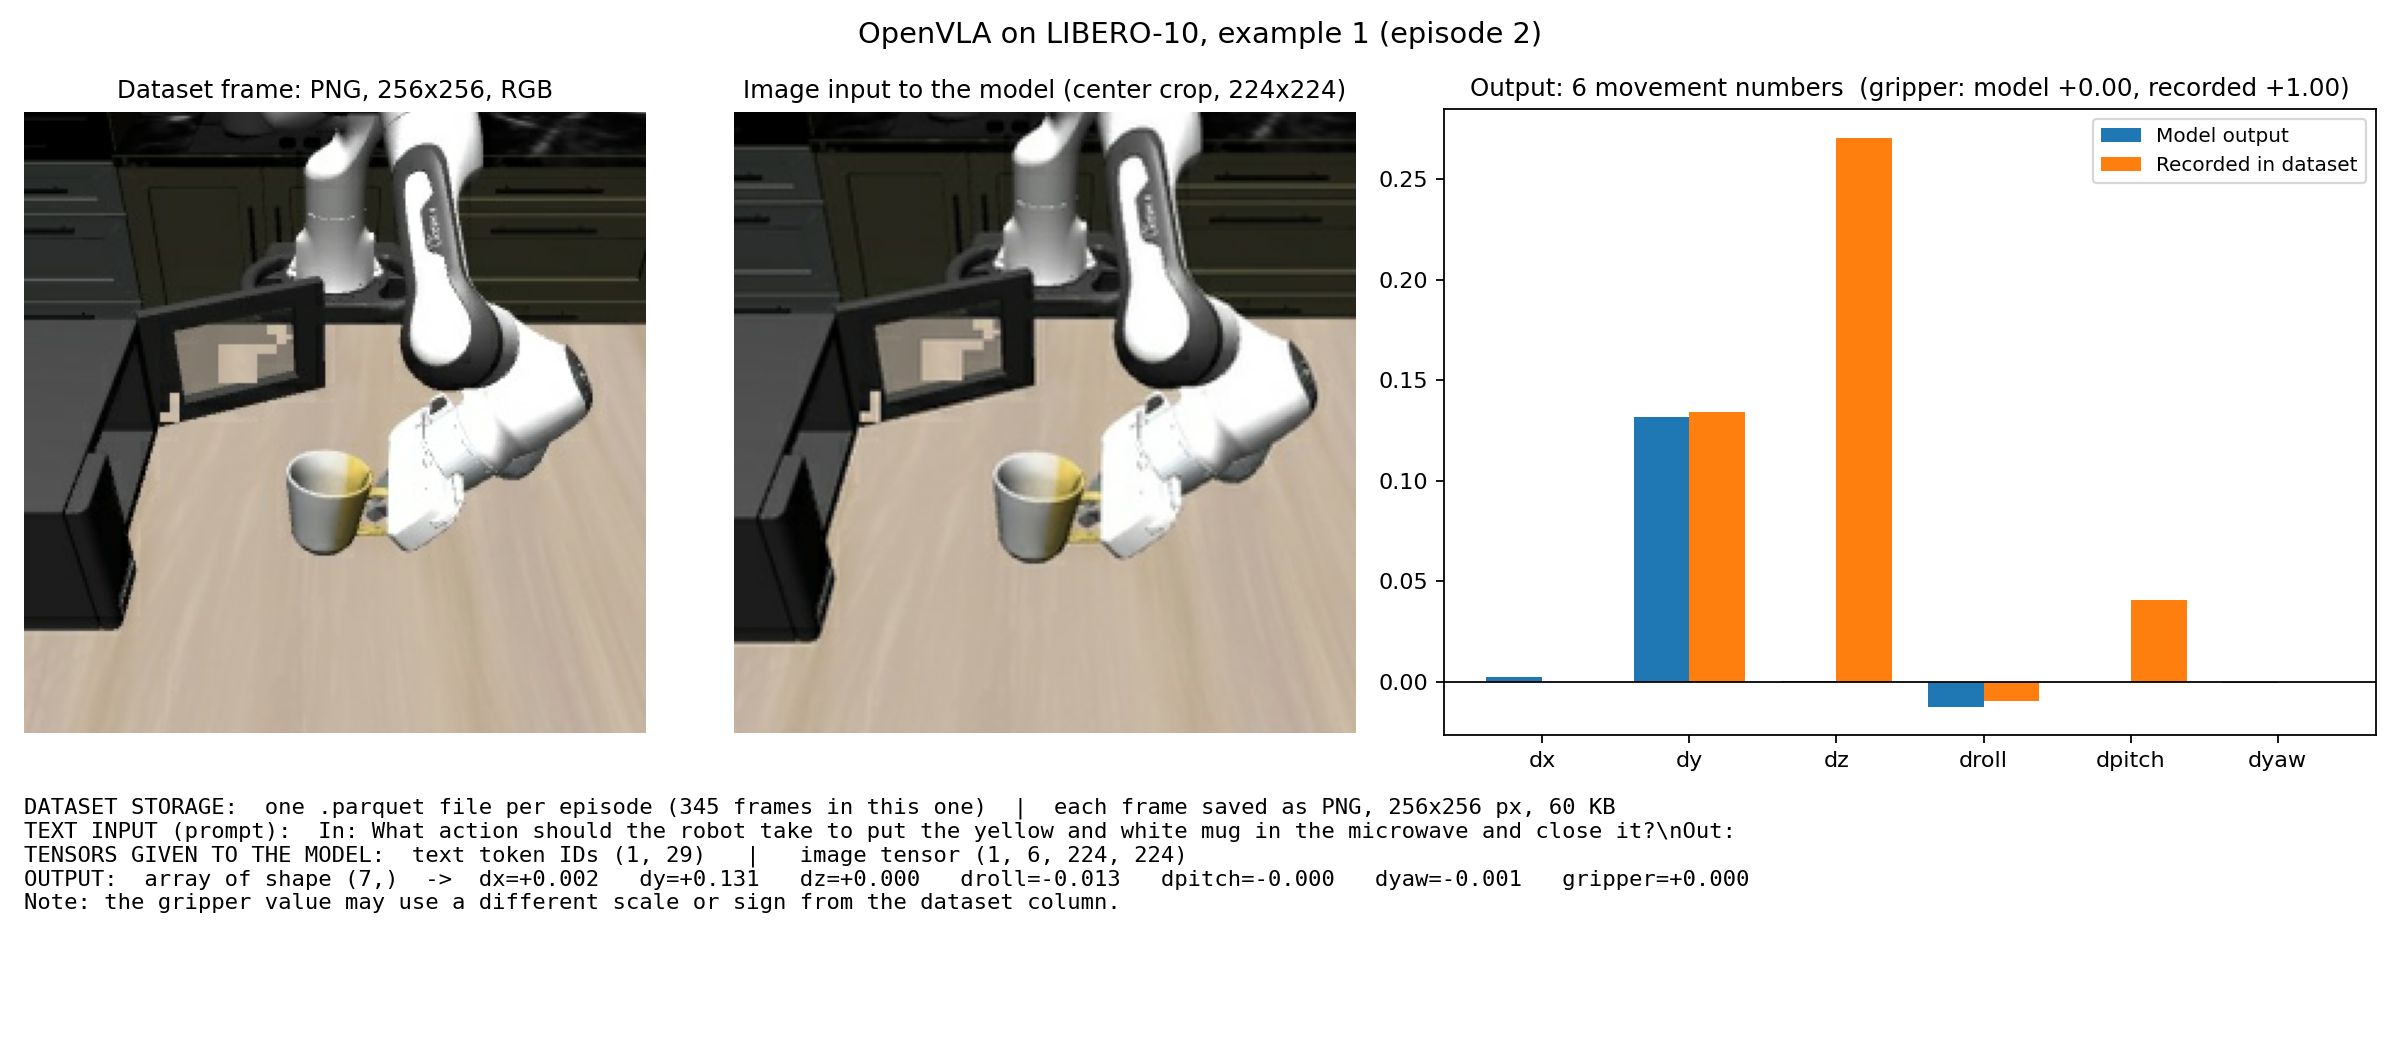

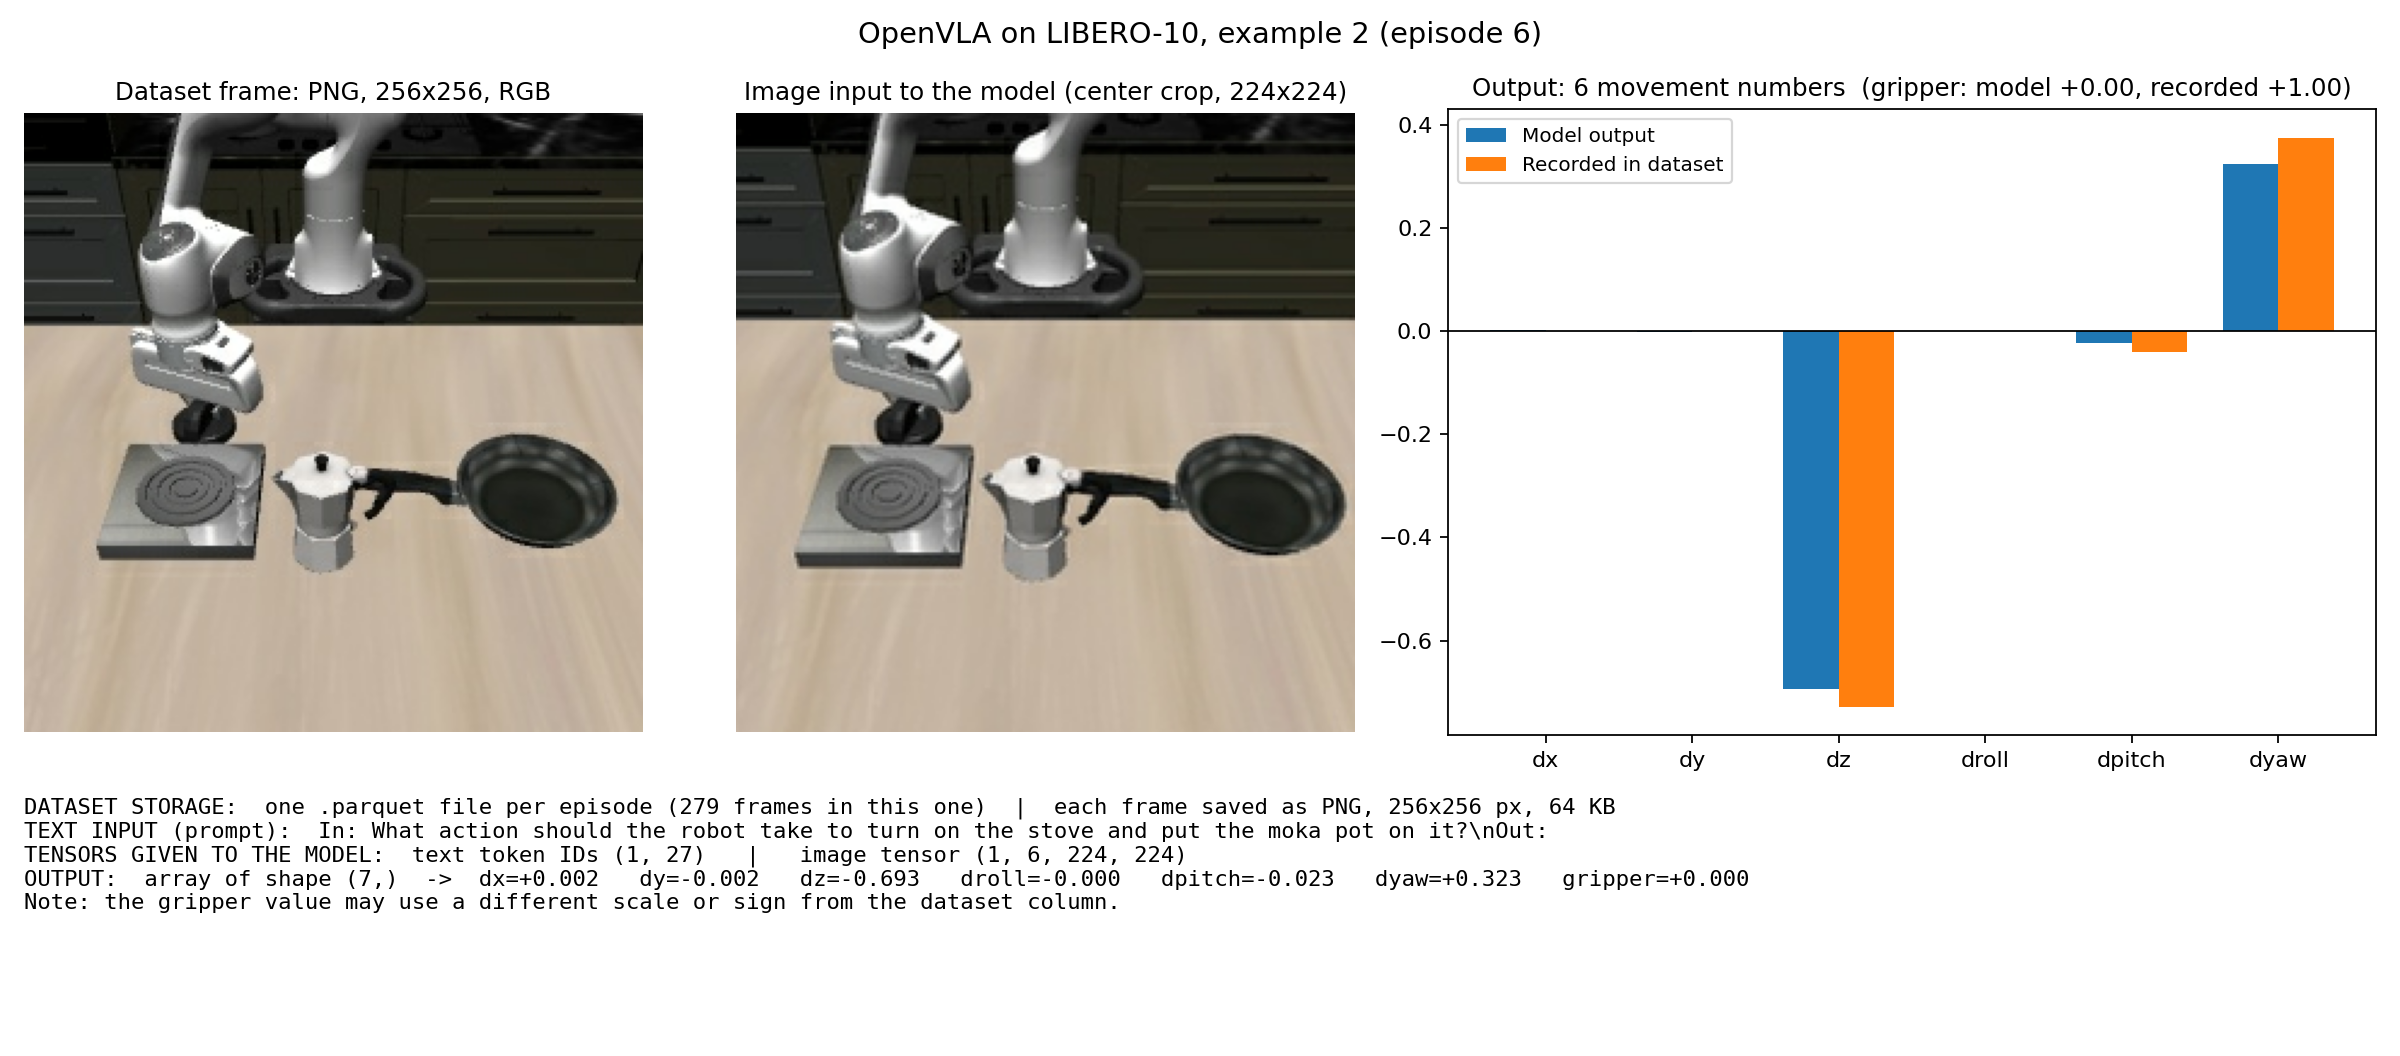

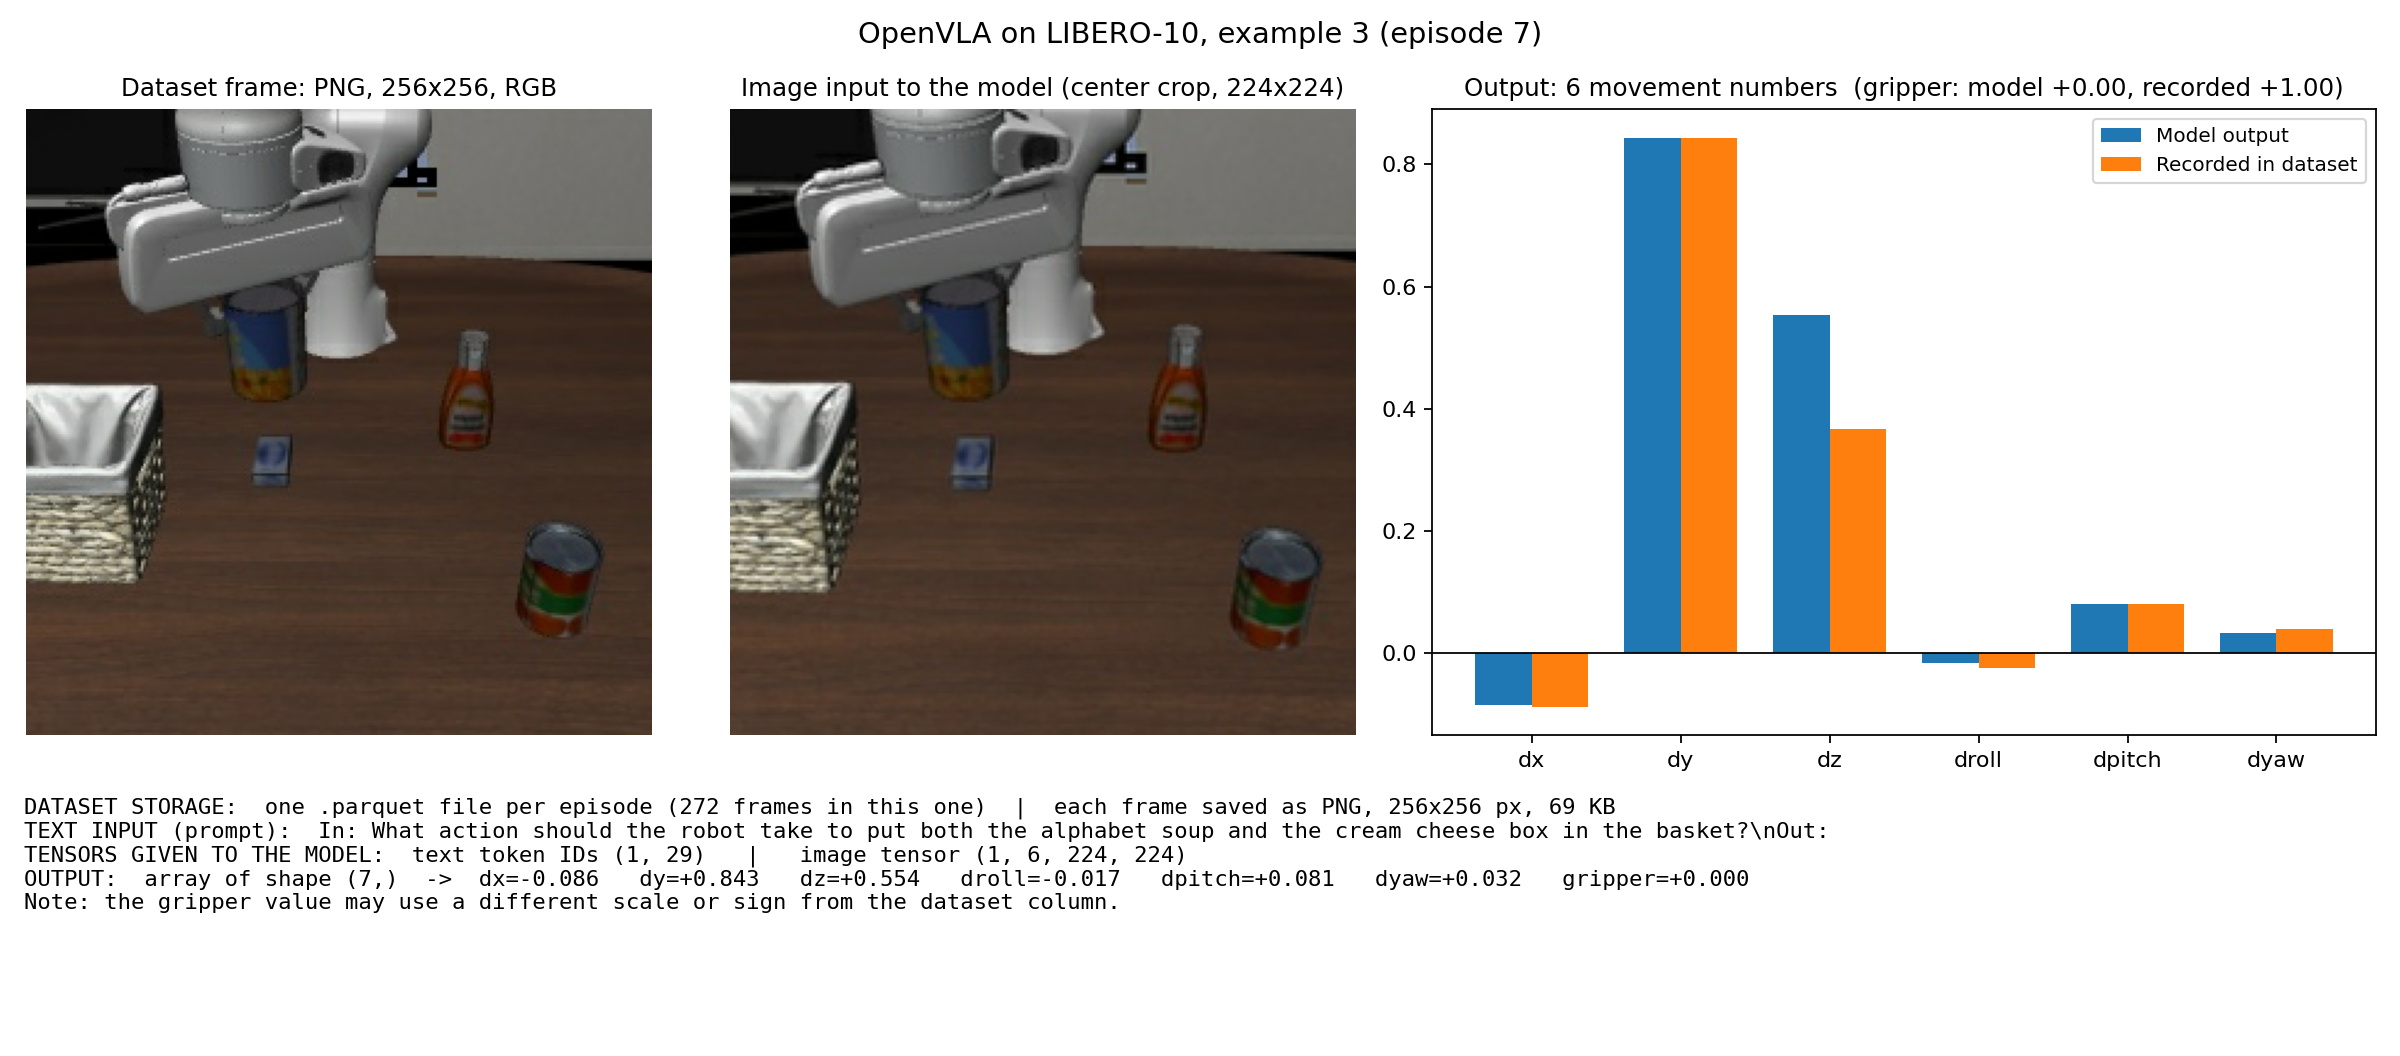

In [ ]:
!MPLBACKEND=Agg /content/vla_env/bin/python /content/run_openvla.py

import glob
from IPython.display import Image as show, display
for path in sorted(glob.glob("/content/openvla_example_*.png")):
    display(show(path))

In [ ]:
!uv pip install -q --python /content/vla_env/bin/python setuptools
!/content/vla_env/bin/python -c "import bitsandbytes; print('bitsandbytes loads OK')"

bitsandbytes loads OK
